# 阶段 2 · 任务 2：PyTorch 复写 MLP，并核对反向传播

**师兄的要求：PyTorch 复写上一项两层 MLP，将 `loss.backward()` 与 NumPy 手写梯度对照，误差小于 $10^{-6}$。**

本任务沿用任务 1 保存的同一份输入、标签和初始参数。网络仍为 `2 → 64 → 3`、隐藏层 ReLU、平均交叉熵；先在 CPU 上使用 `float64` 做严格对照。

运行前，把本文件保存到项目的 `assignments/07_pytorch_mlp/`，选择已有的 `dl-env` 内核。上一份 notebook 的第 10 节应已生成：

- `assignments/06_numpy_mlp/outputs/spiral_dataset.npz`
- `assignments/06_numpy_mlp/outputs/numpy_mlp_initial.npz`

本 notebook 不会重新生成另一份数据来替代这些文件。先确保两边算的是同一个问题，才有比较梯度的意义。只设置相同随机种子，不能保证 NumPy 和 PyTorch 生成相同的随机权重，因此这里直接复制权重。

| 小节 | 你要完成的工作 |
|---|---|
| 1—2 | 导入工具，读取上一项实验数据和初始参数 |
| 3—4 | 保留 NumPy 参考实现，建立 PyTorch 模型并对齐参数 |
| 5—6 | 核对前向输出、损失，以及四组参数的全部梯度 |
| 7 | 对照一次梯度下降更新，理解 `backward()` 与 `step()` |
| 8—9 | 用 PyTorch 从相同初值训练、画图、保存结果 |
| 10 | 完成理解检查，把重点补充进已有 Obsidian 笔记 |

这是带讲解的参考实现。逐节运行并解释关键代码，尤其是转置、`zero_grad()`、`backward()` 和 `step()` 的作用。


## 1. 导入工具与设置精度

标签使用整数 `torch.long`；坐标和模型参数使用 `torch.float64`。CPU 足以完成这项小实验，暂不需要 GPU。

如果 `import torch` 报错，先确认右上角选择的是之前运行李沐课程代码时使用的 `dl-env` 内核。


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from pathlib import Path
import json
import csv

import torch
from torch import nn

np.set_printoptions(precision=6, suppress=True)
torch.set_printoptions(precision=6, sci_mode=False)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

DEVICE = torch.device("cpu")
DTYPE = torch.float64
GRADIENT_TOLERANCE = 1e-6

print("NumPy 版本：", np.__version__)
print("PyTorch 版本：", torch.__version__)
print("比较环境：", DEVICE, DTYPE)


NumPy 版本： 2.3.5
PyTorch 版本： 2.5.1+cpu
比较环境： cpu torch.float64


## 2. 读取上一项任务的输入和初始参数

代码会兼容两种常见内核工作目录：项目根目录、`07_pytorch_mlp` 所在目录。若没有自动找到，可以把 `NUMPY_OUTPUT_DIR` 改为上一项 `outputs` 的实际路径，例如 `Path(r"C:\Users\ET\projects\dl-learning-journey\assignments\06_numpy_mlp\outputs")`。

比较时读取的是 `numpy_mlp_initial.npz`。之后两边都从这组初始权重开始；不用各自随机初始化，也不把一边的训练后参数与另一边的初值相比。


In [2]:
# 自动寻找；如果需要手动指定，把 None 改为 Path(r"你的 outputs 完整路径")
NUMPY_OUTPUT_DIR = None

cwd = Path.cwd()
if NUMPY_OUTPUT_DIR is None:
    candidates = [
        cwd / "assignments" / "06_numpy_mlp" / "outputs",
        cwd.parent / "06_numpy_mlp" / "outputs",
        cwd / "06_numpy_mlp" / "outputs",
        cwd / "outputs",
    ]
    numpy_output_dir = next(
        (p for p in candidates
         if (p / "spiral_dataset.npz").is_file()
         and (p / "numpy_mlp_initial.npz").is_file()),
        None,
    )
else:
    numpy_output_dir = Path(NUMPY_OUTPUT_DIR).expanduser()

if numpy_output_dir is None:
    raise FileNotFoundError(
        "未找到上一项的数据和初始参数。请先运行任务 1 第 10 节保存结果，"
        "或在本单元设置 NUMPY_OUTPUT_DIR。"
    )

with np.load(numpy_output_dir / "spiral_dataset.npz", allow_pickle=False) as saved:
    X_train = np.array(saved["X_train"], dtype=np.float64, copy=True)
    y_train = np.array(saved["y_train"], dtype=np.int64, copy=True)
    X_val = np.array(saved["X_val"], dtype=np.float64, copy=True)
    y_val = np.array(saved["y_val"], dtype=np.int64, copy=True)

with np.load(numpy_output_dir / "numpy_mlp_initial.npz", allow_pickle=False) as saved:
    initial_params = {name: np.array(saved[name], dtype=np.float64, copy=True)
                      for name in ["W1", "b1", "W2", "b2"]}

INPUT_DIM, HIDDEN_UNITS = initial_params["W1"].shape
NUM_CLASSES = initial_params["W2"].shape[1]
assert initial_params["b1"].shape == (1, HIDDEN_UNITS)
assert initial_params["W2"].shape == (HIDDEN_UNITS, NUM_CLASSES)
assert initial_params["b2"].shape == (1, NUM_CLASSES)
assert X_train.shape[1] == X_val.shape[1] == INPUT_DIM
assert y_train.shape == (len(X_train),) and y_val.shape == (len(X_val),)
assert np.isfinite(X_train).all() and np.isfinite(X_val).all()
assert all(np.isfinite(value).all() for value in initial_params.values())
assert np.all((y_train >= 0) & (y_train < NUM_CLASSES))
assert np.all((y_val >= 0) & (y_val < NUM_CLASSES))

X_train_t = torch.tensor(X_train, dtype=DTYPE, device=DEVICE)
y_train_t = torch.tensor(y_train, dtype=torch.long, device=DEVICE)
X_val_t = torch.tensor(X_val, dtype=DTYPE, device=DEVICE)
y_val_t = torch.tensor(y_val, dtype=torch.long, device=DEVICE)

print("已读取：", numpy_output_dir.resolve())
print("训练坐标、标签：", X_train.shape, y_train.shape)
print("验证坐标、标签：", X_val.shape, y_val.shape)
print("网络维度：", INPUT_DIM, "→", HIDDEN_UNITS, "→", NUM_CLASSES)
print("训练坐标 dtype：", X_train_t.dtype, "标签 dtype：", y_train_t.dtype)


已读取： [参考运行项目]/assignments/06_numpy_mlp/outputs
训练坐标、标签： (480, 2) (480,)
验证坐标、标签： (120, 2) (120,)
网络维度： 2 → 64 → 3
训练坐标 dtype： torch.float64 标签 dtype： torch.int64


## 3. NumPy 参考计算

下面保留上一项的前向和手写反向公式，方便在同一份 notebook 中进行对照；无需运行上一份 notebook 的训练单元。

$$Z_1=XW_1+b_1,\quad A_1=\operatorname{ReLU}(Z_1),\quad Z_2=A_1W_2+b_2.$$

$$L=-\frac1N\sum_i\log P_{i,y_i},\qquad D_2=(P-T)/N.$$

$$\nabla W_2=A_1^\mathsf TD_2,\quad\nabla b_2=\sum_iD_{2,i:},$$
$$D_1=(D_2W_2^\mathsf T)\odot\mathbf1[Z_1>0],\quad
\nabla W_1=X^\mathsf TD_1,\quad\nabla b_1=\sum_iD_{1,i:}.$$

与上一项一样，损失按样本平均，没有额外的正则化项。


In [3]:
def numpy_forward(X, params):
    Z1 = X @ params["W1"] + params["b1"]
    A1 = np.maximum(Z1, 0.0)
    logits = A1 @ params["W2"] + params["b2"]

    shifted = logits - logits.max(axis=1, keepdims=True)
    log_probs = shifted - np.log(np.exp(shifted).sum(axis=1, keepdims=True))
    probs = np.exp(log_probs)
    return logits, {"X": X, "Z1": Z1, "A1": A1,
                    "log_probs": log_probs, "probs": probs}


def numpy_loss(cache, labels):
    return float(-cache["log_probs"][np.arange(len(labels)), labels].mean())


def numpy_backward(params, cache, labels):
    dZ2 = cache["probs"].copy()
    dZ2[np.arange(len(labels)), labels] -= 1.0
    dZ2 /= len(labels)

    dW2 = cache["A1"].T @ dZ2
    db2 = dZ2.sum(axis=0, keepdims=True)
    dA1 = dZ2 @ params["W2"].T
    dZ1 = dA1 * (cache["Z1"] > 0)
    dW1 = cache["X"].T @ dZ1
    db1 = dZ1.sum(axis=0, keepdims=True)
    return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}


numpy_logits, numpy_cache = numpy_forward(X_train, initial_params)
numpy_loss_value = numpy_loss(numpy_cache, y_train)
numpy_grads = numpy_backward(initial_params, numpy_cache, y_train)
print("NumPy 初始平均交叉熵：", numpy_loss_value)


NumPy 初始平均交叉熵： 1.2464865997853067


## 4. 建立 PyTorch 模型，并复制完全相同的权重

PyTorch 的 `nn.Linear` 计算 $Y=XW_{\mathrm{torch}}^\mathsf T+b$，因此其权重按“输出数 × 输入数”存放。上一项 NumPy 直接计算 $XW_{\mathrm{numpy}}$，所以两边应满足：

$$W_{\mathrm{torch}}=W_{\mathrm{numpy}}^\mathsf T.$$

| 参数 | NumPy 形状 | PyTorch 形状 | 复制方式 |
|---|---|---|---|
| 第一层权重 | $(2,64)$ | $(64,2)$ | 转置 |
| 第一层偏置 | $(1,64)$ | $(64,)$ | 去掉第一维 |
| 第二层权重 | $(64,3)$ | $(3,64)$ | 转置 |
| 第二层偏置 | $(1,3)$ | $(3,)$ | 去掉第一维 |

`torch.no_grad()` 用在参数复制过程中，避免把赋初值记录为需要求导的计算；复制后模型参数依然可以正常求梯度。

模型输出类别分数 `logits`。`nn.CrossEntropyLoss` 内部完成稳定的 LogSoftmax 与负对数似然计算，因此不要在模型末尾另加 Softmax 再传给它。需要查看概率时，再单独使用 `torch.softmax`。


In [4]:
class TwoLayerMLP(nn.Module):
    def __init__(self, input_dim, hidden_units, num_classes):
        super().__init__()
        self.hidden = nn.Linear(input_dim, hidden_units)
        self.output = nn.Linear(hidden_units, num_classes)

    def forward(self, X):
        hidden_values = torch.relu(self.hidden(X))
        return self.output(hidden_values)


def build_matched_model(numpy_params):
    input_dim, hidden_units = numpy_params["W1"].shape
    num_classes = numpy_params["W2"].shape[1]
    model = TwoLayerMLP(input_dim, hidden_units, num_classes).to(
        device=DEVICE, dtype=DTYPE
    )
    with torch.no_grad():
        model.hidden.weight.copy_(torch.tensor(numpy_params["W1"].T, dtype=DTYPE))
        model.hidden.bias.copy_(torch.tensor(numpy_params["b1"].reshape(-1), dtype=DTYPE))
        model.output.weight.copy_(torch.tensor(numpy_params["W2"].T, dtype=DTYPE))
        model.output.bias.copy_(torch.tensor(numpy_params["b2"].reshape(-1), dtype=DTYPE))
    return model


def parameters_as_numpy(model):
    return {
        "W1": model.hidden.weight.detach().cpu().numpy().T.copy(),
        "b1": model.hidden.bias.detach().cpu().numpy().reshape(1, -1).copy(),
        "W2": model.output.weight.detach().cpu().numpy().T.copy(),
        "b2": model.output.bias.detach().cpu().numpy().reshape(1, -1).copy(),
    }


model = build_matched_model(initial_params)
criterion = nn.CrossEntropyLoss(reduction="mean")
print(model)
print("参数总数：", sum(parameter.numel() for parameter in model.parameters()))
for name, parameter in model.named_parameters():
    print(name, tuple(parameter.shape), parameter.dtype)

copied_params = parameters_as_numpy(model)
for name in initial_params:
    assert np.array_equal(copied_params[name], initial_params[name])
print("两边的初始参数完全相同。")


TwoLayerMLP(
  (hidden): Linear(in_features=2, out_features=64, bias=True)
  (output): Linear(in_features=64, out_features=3, bias=True)
)
参数总数： 387
hidden.weight (64, 2) torch.float64
hidden.bias (64,) torch.float64
output.weight (3, 64) torch.float64
output.bias (3,) torch.float64
两边的初始参数完全相同。


## 5. 先核对前向计算与损失

前向输出与损失一致后，再比较反向梯度。这里比较：类别分数、Softmax 概率和平均交叉熵。

差异通常接近浮点舍入误差。由于矩阵运算库和运算顺序不同，不要求每个中间结果在二进制层面完全相同。


In [5]:
with torch.no_grad():
    torch_logits = model(X_train_t)
    torch_probs = torch.softmax(torch_logits, dim=1)
    torch_loss_value = criterion(torch_logits, y_train_t).item()

forward_report = {
    "logits_max_absolute_error": float(np.max(np.abs(
        numpy_logits - torch_logits.cpu().numpy()))),
    "probability_max_absolute_error": float(np.max(np.abs(
        numpy_cache["probs"] - torch_probs.cpu().numpy()))),
    "loss_absolute_error": abs(numpy_loss_value - torch_loss_value),
}
print(f"NumPy loss： {numpy_loss_value:.12f}")
print(f"PyTorch loss：{torch_loss_value:.12f}")
for name, error in forward_report.items():
    print(f"{name}: {error:.3e}")
    assert error < GRADIENT_TOLERANCE


NumPy loss： 1.246486599785
PyTorch loss：1.246486599785
logits_max_absolute_error: 4.441e-16
probability_max_absolute_error: 2.220e-16
loss_absolute_error: 2.220e-16


## 6. 用 `loss.backward()` 计算并对照全部梯度

这一步先清除旧梯度，再重新建立计算图。上一节位于 `no_grad()` 中的结果用于查看数值，不能直接用来反向传播。

`loss.backward()` 会沿计算图计算梯度，把结果放进每个参数的 `.grad`；这一步本身不更新参数。重复调用反向传播时梯度会累加，所以每次独立计算前要清除旧梯度。

比较权重梯度时也要转置，偏置梯度则恢复成 NumPy 的二维形状。

每组参数的误差定义为：

$$e=\max_j|g^{\mathrm{numpy}}_j-g^{\mathrm{torch}}_j|.$$

**验收标准：四组误差都小于 $10^{-6}$。**默认网络共比较 387 个参数，而非只检查某个权重。


In [6]:
# 每次重新运行本单元都从相同初值开始
model = build_matched_model(initial_params)
model.zero_grad(set_to_none=True)
logits = model(X_train_t)
loss = criterion(logits, y_train_t)
loss.backward()

torch_grads = {
    "W1": model.hidden.weight.grad.detach().cpu().numpy().T.copy(),
    "b1": model.hidden.bias.grad.detach().cpu().numpy().reshape(1, -1).copy(),
    "W2": model.output.weight.grad.detach().cpu().numpy().T.copy(),
    "b2": model.output.bias.grad.detach().cpu().numpy().reshape(1, -1).copy(),
}

gradient_report = []
print(f"{'参数':<5} {'形状':<13} {'最大绝对误差':>16} {'结果':>8}")
for name in ["W1", "b1", "W2", "b2"]:
    assert numpy_grads[name].shape == torch_grads[name].shape
    error = float(np.max(np.abs(numpy_grads[name] - torch_grads[name])))
    passed = bool(error < GRADIENT_TOLERANCE)
    gradient_report.append({"parameter": name, "shape": list(numpy_grads[name].shape),
                            "max_absolute_error": error, "passed": passed})
    print(f"{name:<5} {str(numpy_grads[name].shape):<13} {error:>16.3e}"
          f" {'PASS' if passed else 'FAIL':>8}")
    assert passed, f"{name} 的梯度误差未达到要求，请核对数据、权重与损失定义。"

max_gradient_error = max(item["max_absolute_error"] for item in gradient_report)
print("共比较参数数：", sum(value.size for value in numpy_grads.values()))
print(f"最大梯度误差：{max_gradient_error:.3e} < {GRADIENT_TOLERANCE:.0e}")
print("四组梯度对照全部通过。")


参数    形状                      最大绝对误差       结果
W1    (2, 64)              6.939e-18     PASS
b1    (1, 64)              6.245e-17     PASS
W2    (64, 3)              8.327e-17     PASS
b2    (1, 3)               4.163e-17     PASS
共比较参数数： 387
最大梯度误差：8.327e-17 < 1e-06
四组梯度对照全部通过。


## 7. 再核对一次参数更新

NumPy 更新：`parameter -= learning_rate * gradient`。

PyTorch 使用普通 SGD：`optimizer.step()`。这里没有动量和权重衰减，因此它执行同一个更新公式。

四步的作用要分清：

1. `optimizer.zero_grad()`：清除上一次留下的梯度。
2. `logits = model(X)` 与 `loss = criterion(logits, y)`：前向计算。
3. `loss.backward()`：计算参数梯度。
4. `optimizer.step()`：利用梯度修改参数。

本单元单独从初值建立模型，因此重复运行不会意外多更新一轮。


In [7]:
LEARNING_RATE = 0.5

numpy_updated = {name: value - LEARNING_RATE * numpy_grads[name]
                 for name, value in initial_params.items()}

step_model = build_matched_model(initial_params)
step_optimizer = torch.optim.SGD(step_model.parameters(), lr=LEARNING_RATE)
step_optimizer.zero_grad(set_to_none=True)
step_loss = criterion(step_model(X_train_t), y_train_t)
step_loss.backward()
step_optimizer.step()
torch_updated = parameters_as_numpy(step_model)

update_report = {}
for name in initial_params:
    error = float(np.max(np.abs(numpy_updated[name] - torch_updated[name])))
    update_report[name] = error
    print(f"更新后 {name} 最大绝对误差：{error:.3e}")
    assert error < GRADIENT_TOLERANCE

_, updated_cache = numpy_forward(X_train, numpy_updated)
numpy_updated_loss = numpy_loss(updated_cache, y_train)
with torch.no_grad():
    torch_updated_loss = criterion(step_model(X_train_t), y_train_t).item()
print(f"一步更新后 NumPy loss： {numpy_updated_loss:.12f}")
print(f"一步更新后 PyTorch loss：{torch_updated_loss:.12f}")


更新后 W1 最大绝对误差：1.735e-18
更新后 b1 最大绝对误差：3.123e-17
更新后 W2 最大绝对误差：2.776e-17
更新后 b2 最大绝对误差：2.082e-17
一步更新后 NumPy loss： 0.891883459754
一步更新后 PyTorch loss：0.891883459754


## 8. 用 PyTorch 从相同初值训练

保持上一项设置：全批量梯度下降，学习率 0.5，2000 个 epoch。每个 epoch 使用全部训练样本并更新一次；验证集不参加梯度计算。

训练单元再次建立新模型，因此不会接着第 7 节的那一步继续训练。

`train()` / `eval()` 控制某些层的训练或评估行为；`torch.no_grad()` 控制是否记录求导图。本例只有 Linear 和 ReLU，但先养成完整训练循环的写法。


In [8]:
NUM_EPOCHS = 2000
LOG_EVERY = 100

train_model = build_matched_model(initial_params)
optimizer = torch.optim.SGD(train_model.parameters(), lr=LEARNING_RATE)
history = {"epoch": [], "train_loss": [], "val_loss": [],
           "train_accuracy": [], "val_accuracy": []}


def evaluate_torch(model, features, labels):
    model.eval()
    with torch.no_grad():
        scores = model(features)
        loss_value = criterion(scores, labels).item()
        accuracy = (scores.argmax(dim=1) == labels).to(DTYPE).mean().item()
    return loss_value, accuracy


def record_metrics(epoch):
    train_loss, train_acc = evaluate_torch(train_model, X_train_t, y_train_t)
    val_loss, val_acc = evaluate_torch(train_model, X_val_t, y_val_t)
    for name, value in zip(history, [epoch, train_loss, val_loss, train_acc, val_acc]):
        history[name].append(value)
    print(f"epoch {epoch:4d} | loss {train_loss:.5f} / {val_loss:.5f}"
          f" | acc {train_acc:.2%} / {val_acc:.2%}")


print("每行顺序：训练 / 验证")
record_metrics(0)
for epoch in range(1, NUM_EPOCHS + 1):
    train_model.train()
    optimizer.zero_grad(set_to_none=True)
    train_logits = train_model(X_train_t)
    train_loss = criterion(train_logits, y_train_t)
    train_loss.backward()
    optimizer.step()

    if epoch % LOG_EVERY == 0 or epoch == NUM_EPOCHS:
        record_metrics(epoch)

final_train_loss, final_train_accuracy = evaluate_torch(train_model, X_train_t, y_train_t)
final_val_loss, final_val_accuracy = evaluate_torch(train_model, X_val_t, y_val_t)
print(f"最终训练准确率：{final_train_accuracy:.2%}")
print(f"最终验证准确率：{final_val_accuracy:.2%}")


每行顺序：训练 / 验证
epoch    0 | loss 1.24649 / 1.28176 | acc 20.00% / 15.00%
epoch  100 | loss 0.24446 / 0.29481 | acc 95.83% / 92.50%
epoch  200 | loss 0.11920 / 0.15212 | acc 99.38% / 99.17%
epoch  300 | loss 0.07575 / 0.10096 | acc 99.79% / 99.17%
epoch  400 | loss 0.05437 / 0.07491 | acc 100.00% / 100.00%
epoch  500 | loss 0.04187 / 0.05936 | acc 100.00% / 100.00%
epoch  600 | loss 0.03376 / 0.04896 | acc 100.00% / 100.00%
epoch  700 | loss 0.02808 / 0.04151 | acc 100.00% / 100.00%
epoch  800 | loss 0.02393 / 0.03592 | acc 100.00% / 100.00%
epoch  900 | loss 0.02076 / 0.03151 | acc 100.00% / 100.00%
epoch 1000 | loss 0.01825 / 0.02806 | acc 100.00% / 100.00%
epoch 1100 | loss 0.01626 / 0.02524 | acc 100.00% / 100.00%
epoch 1200 | loss 0.01464 / 0.02295 | acc 100.00% / 100.00%
epoch 1300 | loss 0.01330 / 0.02102 | acc 100.00% / 100.00%
epoch 1400 | loss 0.01216 / 0.01937 | acc 100.00% / 100.00%
epoch 1500 | loss 0.01118 / 0.01794 | acc 100.00% / 100.00%
epoch 1600 | loss 0.01034 / 0.01668

## 9. 绘图并保存本项结果

保存梯度误差表、实验指标、训练曲线、分类区域和训练后的 `state_dict`。如果从项目根目录运行，优先使用已有的 `assignments/07_pytorch_mlp`；如果工作目录就是任务文件夹，则直接使用当前目录。

`state_dict` 保存模型参数，不包含模型类的 Python 定义；后续加载时仍需创建相同结构的模型。


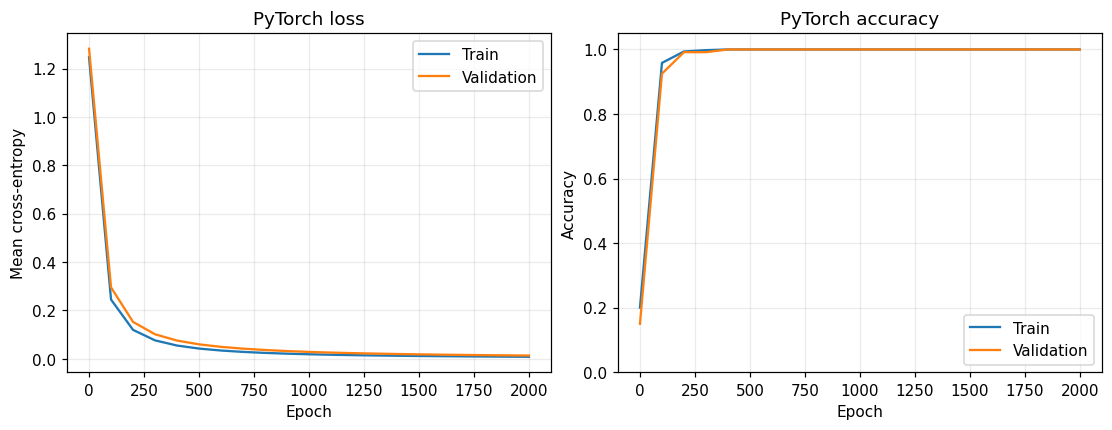

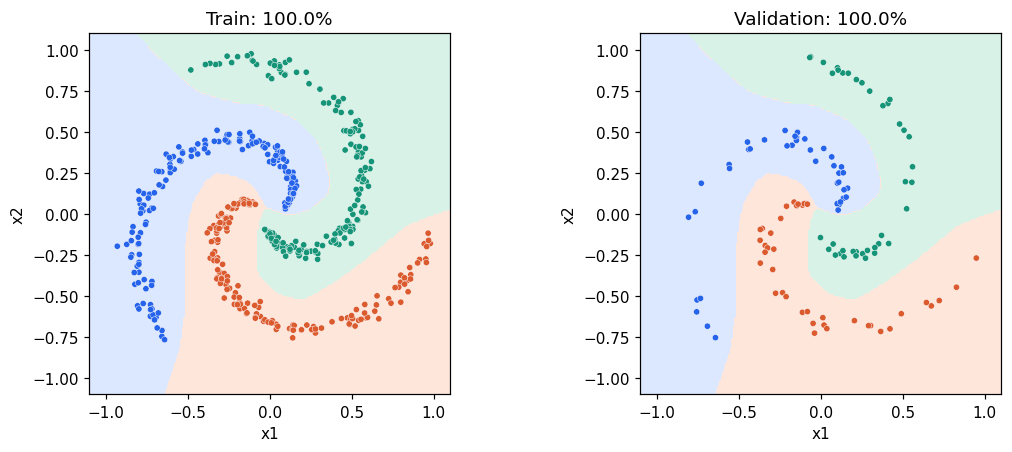

In [9]:
fig_curves, axes = plt.subplots(1, 2, figsize=(10, 3.8), constrained_layout=True)
axes[0].plot(history["epoch"], history["train_loss"], label="Train")
axes[0].plot(history["epoch"], history["val_loss"], label="Validation")
axes[0].set(title="PyTorch loss", xlabel="Epoch", ylabel="Mean cross-entropy")
axes[1].plot(history["epoch"], history["train_accuracy"], label="Train")
axes[1].plot(history["epoch"], history["val_accuracy"], label="Validation")
axes[1].set(title="PyTorch accuracy", xlabel="Epoch", ylabel="Accuracy", ylim=(0, 1.05))
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend()
plt.show()

grid_x, grid_y = np.meshgrid(np.linspace(-1.1, 1.1, 240),
                           np.linspace(-1.1, 1.1, 240))
grid_points = np.column_stack((grid_x.ravel(), grid_y.ravel()))
with torch.no_grad():
    grid_tensor = torch.tensor(grid_points, dtype=DTYPE, device=DEVICE)
    grid_labels = train_model(grid_tensor).argmax(dim=1).cpu().numpy().reshape(grid_x.shape)

point_cmap = ListedColormap(["#2563eb", "#db5a2e", "#159477"])
region_cmap = ListedColormap(["#dce8ff", "#ffe6db", "#d8f2e8"])
fig_regions, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for ax, features, labels, title in [
    (axes[0], X_train, y_train, f"Train: {final_train_accuracy:.1%}"),
    (axes[1], X_val, y_val, f"Validation: {final_val_accuracy:.1%}"),
]:
    ax.contourf(grid_x, grid_y, grid_labels, levels=[-0.5, 0.5, 1.5, 2.5], cmap=region_cmap)
    ax.scatter(features[:, 0], features[:, 1], c=labels, cmap=point_cmap,
               vmin=0, vmax=2, s=17, edgecolors="white", linewidths=0.3)
    ax.set(title=title, xlabel="x1", ylabel="x2", xlim=(-1.1, 1.1), ylim=(-1.1, 1.1))
    ax.set_aspect("equal")
plt.show()


In [10]:
cwd = Path.cwd()
candidate = cwd / "assignments" / "07_pytorch_mlp"
assignment_dir = candidate if candidate.is_dir() else cwd
output_dir = assignment_dir / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)

fig_curves.savefig(output_dir / "pytorch_training_curves.png", dpi=160, bbox_inches="tight")
fig_regions.savefig(output_dir / "pytorch_decision_regions.png", dpi=160, bbox_inches="tight")
torch.save(train_model.state_dict(), output_dir / "pytorch_mlp_state_dict.pt")

with (output_dir / "gradient_comparison.csv").open("w", newline="", encoding="utf-8") as file:
    writer = csv.writer(file)
    writer.writerow(["parameter", "shape", "max_absolute_error", "passed"])
    for item in gradient_report:
        writer.writerow([item["parameter"], str(tuple(item["shape"])),
                         item["max_absolute_error"], item["passed"]])

experiment = {
    "task": "PyTorch versus NumPy two-layer MLP gradients",
    "numpy_version": np.__version__, "torch_version": torch.__version__,
    "device": str(DEVICE), "dtype": str(DTYPE),
    "input_dim": INPUT_DIM, "hidden_units": HIDDEN_UNITS, "num_classes": NUM_CLASSES,
    "train_samples": len(y_train), "validation_samples": len(y_val),
    "gradient_tolerance": GRADIENT_TOLERANCE,
    "forward_comparison": forward_report, "gradient_comparison": gradient_report,
    "max_gradient_error": max_gradient_error, "single_update_errors": update_report,
    "learning_rate": LEARNING_RATE, "epochs": NUM_EPOCHS,
    "train_loss": final_train_loss, "validation_loss": final_val_loss,
    "train_accuracy": final_train_accuracy, "validation_accuracy": final_val_accuracy,
    "history": history,
}
(output_dir / "comparison_metrics.json").write_text(
    json.dumps(experiment, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("本项结果已保存到：", output_dir.resolve())
print("请再按 Ctrl+S 保存 notebook。")


本项结果已保存到： [参考运行项目]/assignments/07_pytorch_mlp/outputs
请再按 Ctrl+S 保存 notebook。


## 10. 完成标准与重点笔记

- [ ] 两边读取同一份输入、标签与初始参数，均使用 CPU / float64。
- [ ] 能解释 NumPy 权重复制到 `nn.Linear` 时为什么需要转置。
- [ ] 能解释为什么把原始分数传给 `CrossEntropyLoss`，且标签为 `long` 类型。
- [ ] 前向与损失对照通过，`W1、b1、W2、b2` 四组梯度误差均小于 $10^{-6}$。
- [ ] 一次 SGD 更新对照通过，能区分 `zero_grad()`、`backward()` 和 `step()`。
- [ ] PyTorch 训练能正确分类螺旋，结果和 notebook 已保存。

**笔记在已有 Obsidian《两层MLP与反向传播》中集中补充一小段即可：**

1. 一行权重对应关系：$W_{\mathrm{torch}}=W_{\mathrm{numpy}}^\mathsf T$。
2. 一段你自己的梯度误差输出，并解释为什么这能核对上一项的手推实现。
3. 四行训练流程：清梯度 → 前向与损失 → 反向求梯度 → 更新参数。

本次重点是自动求导与手推公式的对应关系。后面的 MNIST 任务会再加入小批量 DataLoader、GPU（可用时）、训练/验证/测试划分等，并集中整理训练循环模板。

**下一项：MNIST 分类器，目标测试准确率至少 98%，保存训练曲线和超参数。**先完成本项对照，之后继续。

官方参考：

- [nn.Linear：公式、权重与偏置形状](https://docs.pytorch.org/docs/stable/generated/torch.nn.Linear.html)
- [nn.CrossEntropyLoss：logits、整数标签与平均损失](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html)
- [Autograd：梯度累加与 backward](https://docs.pytorch.org/docs/stable/generated/torch.autograd.backward.html)
